In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


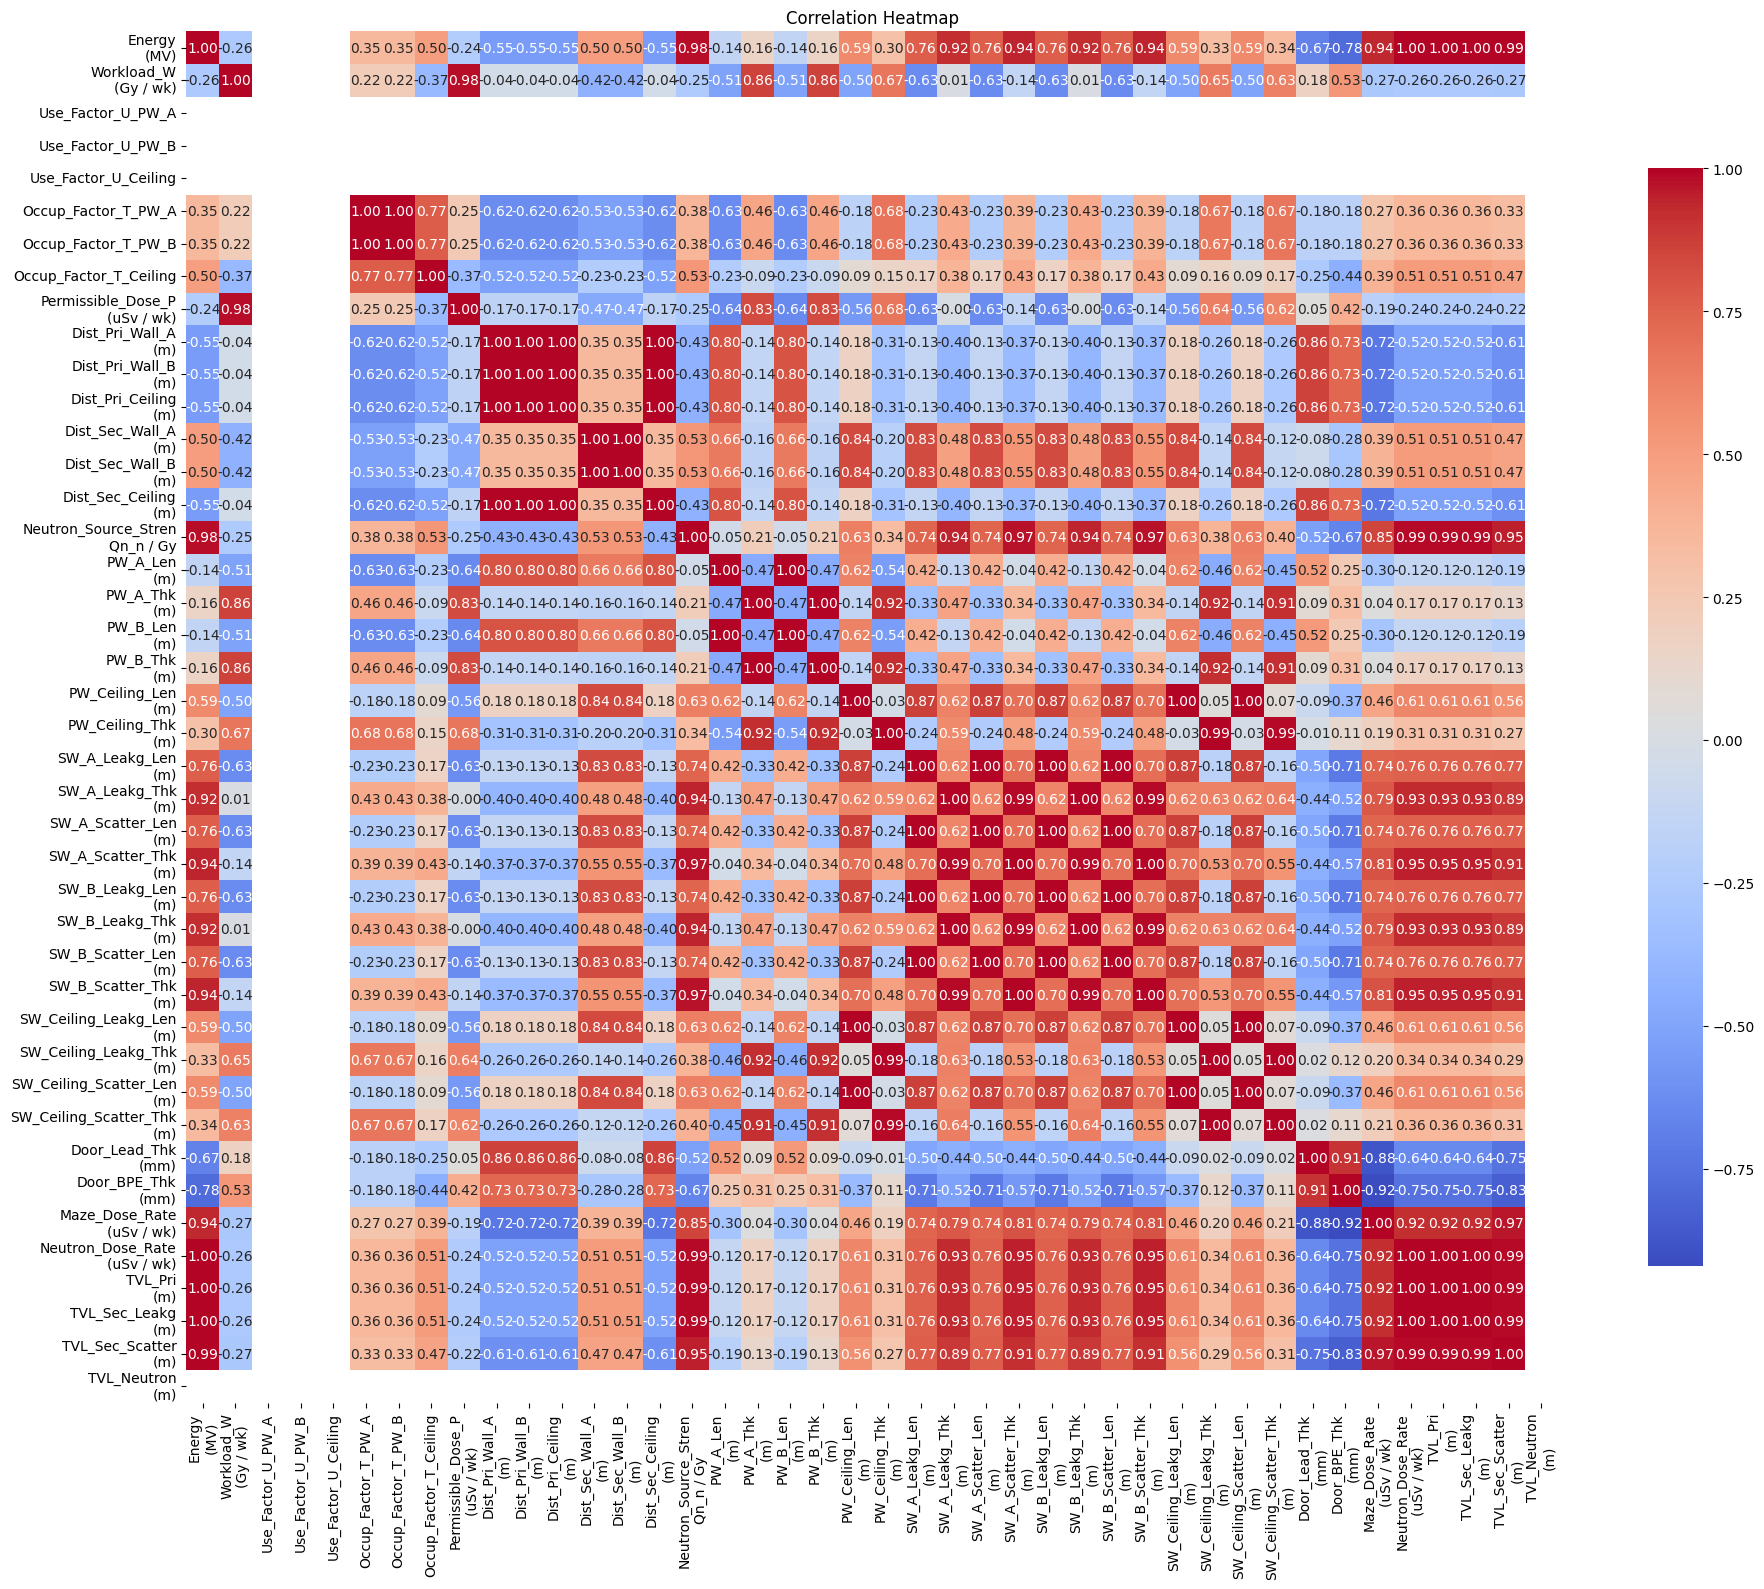

In [ ]:
# ============================================================
# BLOCK 2: Correlation Heatmap
# ============================================================
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

file_path = '/content/drive/MyDrive/Shielding Calculation/Bunker Shielding Data.xlsx'
df_raw = pd.read_excel(file_path, skiprows=1, header=0, usecols="D:AS")

df_numeric = df_raw.apply(pd.to_numeric, errors='coerce')
df_numeric.dropna(axis=1, how='all', inplace=True)

corr = df_numeric.corr()

if not corr.empty:
    plt.figure(figsize=(20, 16))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm',
                square=True, cbar_kws={"shrink": 0.8})
    plt.title('Correlation Heatmap')
    plt.tight_layout()
    plt.show()
else:
    print("No numeric data available for correlation matrix.")

In [ ]:
# ============================================================
# BLOCK 3: Data Loading & Cleaning
# ============================================================
import pandas as pd
import numpy as np

file_path = '/content/drive/MyDrive/Shielding Calculation/Bunker Shielding Data.xlsx'
df = pd.read_excel(file_path, header=1, usecols="D:AS")

print(f"Raw shape: {df.shape}")

# Drop zero-variance columns (Use_Factor x3 are all 0.25, TVL_Neutron is 5/7 NaN + constant)
zero_var_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print(f"Dropping zero-variance columns: {zero_var_cols}")
df = df.drop(columns=zero_var_cols)

# Separate TVL_Neutron — only 2 non-NaN rows, keep aside, don't let it kill dataset
neutron_cols = [c for c in df.columns if 'Neutron' in c]
df_neutron = df[neutron_cols].copy()
df = df.drop(columns=neutron_cols)
print(f"Separated neutron column(s): {neutron_cols}")

print(f"\nWorking dataset shape: {df.shape}")
print(f"Remaining NaNs: {df.isnull().sum().sum()}")
print(df.to_string())

Raw shape: (7, 42)
Dropping zero-variance columns: ['Use_Factor_U_PW_A', 'Use_Factor_U_PW_B', 'Use_Factor_U_Ceiling']
Separated neutron column(s): ['Neutron_Source_Stren\nQn_n / Gy', 'Neutron_Dose_Rate\n(uSv / wk)', 'TVL_Neutron\n(m)']

Working dataset shape: (7, 36)
Remaining NaNs: 0
   Energy\n(MV)  Workload_W\n(Gy / wk)  Occup_Factor_T_PW_A  Occup_Factor_T_PW_B  Occup_Factor_T_Ceiling  Permissible_Dose_P\n(uSv / wk)  Dist_Pri_Wall_A\n(m)  Dist_Pri_Wall_B\n(m)  Dist_Pri_Ceiling\n(m)  Dist_Sec_Wall_A\n(m)  Dist_Sec_Wall_B\n(m)  Dist_Sec_Ceiling\n(m)  PW_A_Len\n(m)  PW_A_Thk\n(m)  PW_B_Len\n(m)  PW_B_Thk\n(m)  PW_Ceiling_Len\n(m)  PW_Ceiling_Thk\n(m)  SW_A_Leakg_Len\n(m)  SW_A_Leakg_Thk\n(m)  SW_A_Scatter_Len\n(m)  SW_A_Scatter_Thk\n(m)  SW_B_Leakg_Len\n(m)  SW_B_Leakg_Thk\n(m)  SW_B_Scatter_Len\n(m)  SW_B_Scatter_Thk\n(m)  SW_Ceiling_Leakg_Len\n(m)  SW_Ceiling_Leakg_Thk\n(m)  SW_Ceiling_Scatter_Len\n(m)  SW_Ceiling_Scatter_Thk\n(m)  Door_Lead_Thk\n(mm)  Door_BPE_Thk\n(mm)  Maze_Dose_R

In [ ]:
# ============================================================
# BLOCK 4: Define Inputs / Outputs by Name
# ============================================================

INPUT_COLS = [
    'Energy\n(MV)',
    'Workload_W\n(Gy / wk)',
    'Occup_Factor_T_PW_A',
    'Occup_Factor_T_PW_B',
    'Occup_Factor_T_Ceiling',
    'Permissible_Dose_P\n(uSv / wk)',
    'Dist_Pri_Wall_A\n(m)',
    'Dist_Pri_Wall_B\n(m)',
    'Dist_Pri_Ceiling\n(m)',
]

OUTPUT_COLS = [c for c in df.columns if c not in INPUT_COLS]

print(f"Inputs  ({len(INPUT_COLS)}): {INPUT_COLS}")
print(f"Outputs ({len(OUTPUT_COLS)}): {OUTPUT_COLS}")

X_orig = df[INPUT_COLS].copy()
Y_orig = df[OUTPUT_COLS].copy()

assert X_orig.isnull().sum().sum() == 0, "NaN in inputs!"
assert Y_orig.isnull().sum().sum() == 0, "NaN in outputs!"
print("\nNo NaN in X or Y.")

# Log-transform outputs: radiation attenuation is exponential
if (Y_orig <= 0).any().any():
    print("WARNING: Some Y <= 0, using log1p.")
    Y_transformed = np.log1p(Y_orig)
else:
    Y_transformed = np.log(Y_orig)

print(f"\nX shape: {X_orig.shape}")
print(f"Y shape: {Y_transformed.shape}")

Inputs  (9): ['Energy\n(MV)', 'Workload_W\n(Gy / wk)', 'Occup_Factor_T_PW_A', 'Occup_Factor_T_PW_B', 'Occup_Factor_T_Ceiling', 'Permissible_Dose_P\n(uSv / wk)', 'Dist_Pri_Wall_A\n(m)', 'Dist_Pri_Wall_B\n(m)', 'Dist_Pri_Ceiling\n(m)']
Outputs (27): ['Dist_Sec_Wall_A\n(m)', 'Dist_Sec_Wall_B\n(m)', 'Dist_Sec_Ceiling\n(m)', 'PW_A_Len\n(m)', 'PW_A_Thk\n(m)', 'PW_B_Len\n(m)', 'PW_B_Thk\n(m)', 'PW_Ceiling_Len\n(m)', 'PW_Ceiling_Thk\n(m)', 'SW_A_Leakg_Len\n(m)', 'SW_A_Leakg_Thk\n(m)', 'SW_A_Scatter_Len\n(m)', 'SW_A_Scatter_Thk\n(m)', 'SW_B_Leakg_Len\n(m)', 'SW_B_Leakg_Thk\n(m)', 'SW_B_Scatter_Len\n(m)', 'SW_B_Scatter_Thk\n(m)', 'SW_Ceiling_Leakg_Len\n(m)', 'SW_Ceiling_Leakg_Thk\n(m)', 'SW_Ceiling_Scatter_Len\n(m)', 'SW_Ceiling_Scatter_Thk\n(m)', 'Door_Lead_Thk\n(mm)', 'Door_BPE_Thk\n(mm)', 'Maze_Dose_Rate\n(uSv / wk)', 'TVL_Pri\n(m)', 'TVL_Sec_Leakg\n(m)', 'TVL_Sec_Scatter\n(m)']

No NaN in X or Y.

X shape: (7, 9)
Y shape: (7, 27)


Explained variance ratio: [4.52427725e-01 3.24611095e-01 1.47159516e-01 5.74534141e-02
 1.35757793e-02 4.77247030e-03 4.46957377e-33]
Cumulative variance: [0.45242773 0.77703882 0.92419834 0.98165175 0.99522753 1.
 1.        ]


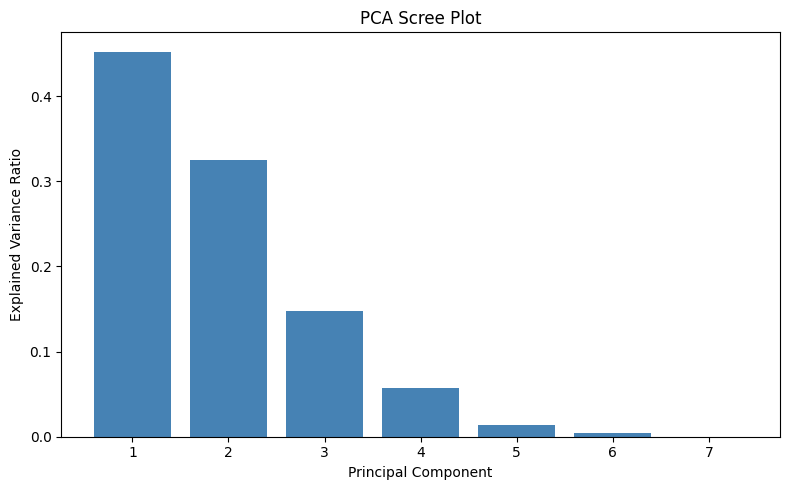

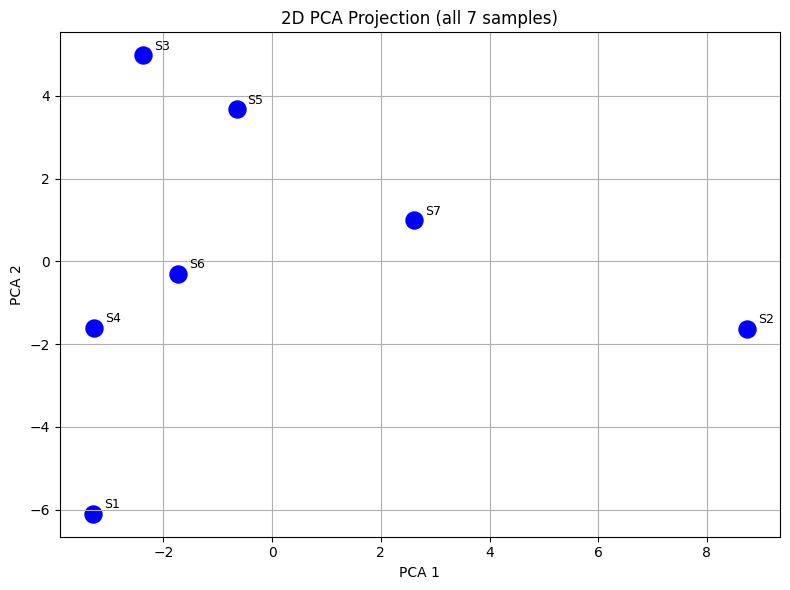

In [ ]:
# ============================================================
# BLOCK 5: PCA on full cleaned dataset (no dropna needed now)
# ============================================================
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

df_all = pd.concat([X_orig, Y_transformed], axis=1)

scaler_pca = StandardScaler()
X_scaled_pca = scaler_pca.fit_transform(df_all)

pca = PCA(n_components=min(df_all.shape[0], df_all.shape[1]))
components = pca.fit_transform(X_scaled_pca)

print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Cumulative variance: {np.cumsum(pca.explained_variance_ratio_)}")

plt.figure(figsize=(8, 5))
plt.bar(range(1, len(pca.explained_variance_ratio_) + 1),
        pca.explained_variance_ratio_, color='steelblue')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('PCA Scree Plot')
plt.tight_layout()
plt.show()

if components.shape[0] >= 2:
    plt.figure(figsize=(8, 6))
    plt.scatter(components[:, 0], components[:, 1], c='blue', s=150)
    for i in range(components.shape[0]):
        plt.annotate(f"S{i+1}", (components[i, 0], components[i, 1]),
                     textcoords="offset points", xytext=(8, 4), fontsize=9)
    plt.xlabel('PCA 1')
    plt.ylabel('PCA 2')
    plt.title('2D PCA Projection (all 7 samples)')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# BLOCK 6: Augmentation Function
# ============================================================

def augment_data(X, Y, times=10, noise_pct=0.02):
    """
    Relative noise: ±noise_pct of each feature's own value.
    Call ONLY on training fold, never on full dataset.
    Y gets half the noise of X (outputs are more physically constrained).
    """
    X_aug, Y_aug = [X.copy()], [Y.copy()]
    for _ in range(times - 1):
        X_noise = X * np.random.normal(0, noise_pct, X.shape)
        Y_noise = Y * np.random.normal(0, noise_pct * 0.5, Y.shape)
        X_aug.append(pd.DataFrame(X.values + X_noise.values, columns=X.columns))
        Y_aug.append(pd.DataFrame(Y.values + Y_noise.values, columns=Y.columns))
    return pd.concat(X_aug, ignore_index=True), pd.concat(Y_aug, ignore_index=True)

In [ ]:
# ============================================================
# BLOCK 7: Metrics Function
# ============================================================
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr

def compute_metrics(y_true, y_pred):
    y_true_np = np.array(y_true)
    y_pred_np = np.array(y_pred)

    r2   = r2_score(y_true_np, y_pred_np, multioutput='uniform_average')
    rmse = np.sqrt(mean_squared_error(y_true_np, y_pred_np))
    mae  = mean_absolute_error(y_true_np, y_pred_np)

    pcc_values = []
    for i in range(len(y_true_np)):
        if np.std(y_true_np[i]) > 0 and np.std(y_pred_np[i]) > 0:
            pcc_values.append(pearsonr(y_true_np[i], y_pred_np[i])[0])
    pcc_avg = np.mean(pcc_values) if pcc_values else np.nan

    return {'R²': round(r2, 4), 'RMSE': round(rmse, 4),
            'MAE': round(mae, 4), 'PCC': round(pcc_avg, 4)}

In [ ]:
# ============================================================
# BLOCK 8: Model Definitions
# ============================================================
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor

def get_models():
    return {
        "Ridge (α=1)":          MultiOutputRegressor(Ridge(alpha=1.0)),
        "Ridge (α=10)":         MultiOutputRegressor(Ridge(alpha=10.0)),
        "Ridge (α=100)":        MultiOutputRegressor(Ridge(alpha=100.0)),
        "Decision Tree":        MultiOutputRegressor(DecisionTreeRegressor(max_depth=3, random_state=42)),
        "Random Forest":        MultiOutputRegressor(RandomForestRegressor(n_estimators=100, max_depth=3, random_state=42)),
        "Gradient Boosting":    MultiOutputRegressor(GradientBoostingRegressor(n_estimators=100, max_depth=2, random_state=42)),
        "SVR":                  MultiOutputRegressor(SVR(kernel='rbf')),
        "Neural Network":       MultiOutputRegressor(MLPRegressor(hidden_layer_sizes=(32,),
                                                                   max_iter=5000,
                                                                   early_stopping=False,
                                                                   random_state=42)),
        "XGBoost":              MultiOutputRegressor(XGBRegressor(n_estimators=100, max_depth=2,
                                                                   random_state=42, verbosity=0)),
    }

In [ ]:
# ============================================================
# BLOCK 9: LOOCV Runner with Augmentation
# ============================================================
from sklearn.model_selection import LeaveOneOut
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

def run_loocv_experiment(X, Y, times, noise_pct, label, use_pca=False, n_pca=3):
    print(f"\n{'='*60}")
    print(f"Experiment: DA x{times}  |  noise_pct={noise_pct*100:.1f}%  |  {label}  |  PCA inputs: {use_pca}")
    print(f"{'='*60}")

    loo = LeaveOneOut()
    n_samples = len(X)
    model_names = list(get_models().keys())
    all_preds = {name: np.zeros_like(Y.values, dtype=float) for name in model_names}

    for fold, (train_idx, test_idx) in enumerate(loo.split(X)):
        X_train_fold = X.iloc[train_idx].reset_index(drop=True)
        Y_train_fold = Y.iloc[train_idx].reset_index(drop=True)
        X_test_fold  = X.iloc[test_idx].reset_index(drop=True)

        # Augment only the training fold
        X_train_aug, Y_train_aug = augment_data(X_train_fold, Y_train_fold,
                                                  times=times, noise_pct=noise_pct)

        # Scale: fit on augmented train only, transform test
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train_aug)
        X_test_scaled  = scaler.transform(X_test_fold)

        # Optional PCA on inputs — fitted on train only
        if use_pca:
            pca_reducer = PCATransform(n_components=n_pca)
            X_train_scaled = pca_reducer.fit_transform(X_train_scaled)
            X_test_scaled  = pca_reducer.transform(X_test_scaled)

        models = get_models()
        for name, model in models.items():
            model.fit(X_train_scaled, Y_train_aug)
            pred = model.predict(X_test_scaled)   # shape (1, n_outputs)
            all_preds[name][test_idx[0]] = pred[0]

        # Per-fold breakdown — identifies which sample is hurting each model
        print(f"\n  Fold {fold+1}/{n_samples} — Test sample: S{test_idx[0]+1}")
        for name in model_names:
            fold_actual = Y.iloc[test_idx].values.flatten()
            fold_pred   = all_preds[name][test_idx[0]]
            fold_mae    = np.mean(np.abs(fold_actual - fold_pred))
            fold_r2     = r2_score(fold_actual.reshape(1, -1).T,
                                   fold_pred.reshape(1, -1).T)   # per-sample R² across outputs
            print(f"    {name:<30}  fold MAE: {fold_mae:.4f}   fold R²: {fold_r2:.4f}")

    # Overall metrics using all LOO predictions
    print(f"\n{'='*60}")
    print(f"Overall Results — {label}")
    print(f"{'='*60}")

    results = {}
    for name in model_names:
        metrics = compute_metrics(Y.values, all_preds[name])
        results[name] = metrics

    results_df = pd.DataFrame(results).T
    print(results_df.to_string())
    return results_df, all_preds

In [ ]:
# ============================================================
# BLOCK 10: Run All DA Experiments
# ============================================================

results_10,   preds_10   = run_loocv_experiment(X_orig, Y_transformed, times=10,   noise_pct=0.02, label="DA_10")
results_50,   preds_50   = run_loocv_experiment(X_orig, Y_transformed, times=50,   noise_pct=0.02, label="DA_50")
results_250,  preds_250  = run_loocv_experiment(X_orig, Y_transformed, times=250,  noise_pct=0.02, label="DA_250")
results_1000, preds_1000 = run_loocv_experiment(X_orig, Y_transformed, times=1000, noise_pct=0.02, label="DA_1000")


Experiment: DA x10  |  noise_pct=2.0%  |  DA_10  |  PCA inputs: False

  Fold 1/7 — Test sample: S1
    Ridge (α=1)                     fold MAE: 1.5258   fold R²: -5.0029
    Ridge (α=10)                    fold MAE: 1.4292   fold R²: -4.9385
    Ridge (α=100)                   fold MAE: 1.4171   fold R²: -13.3620
    Decision Tree                   fold MAE: 0.0828   fold R²: 0.9835
    Random Forest                   fold MAE: 0.0851   fold R²: 0.9781
    Gradient Boosting               fold MAE: 0.0887   fold R²: 0.9687
    SVR                             fold MAE: 0.1674   fold R²: 0.8373
    Neural Network                  fold MAE: 144.9714   fold R²: -38021.3358
    XGBoost                         fold MAE: 0.0695   fold R²: 0.9881

  Fold 2/7 — Test sample: S2
    Ridge (α=1)                     fold MAE: 0.3365   fold R²: 0.1539
    Ridge (α=10)                    fold MAE: 0.3355   fold R²: 0.1489
    Ridge (α=100)                   fold MAE: 0.3439   fold R²: 0.1040
    De

In [ ]:
# ============================================================
# BLOCK 11: Compare DA Levels Side by Side
# ============================================================

print("\n=== R² Comparison Across DA Levels ===")
comparison = pd.DataFrame({
    'DA_10':   results_10['R²'],
    'DA_50':   results_50['R²'],
    'DA_250':  results_250['R²'],
    'DA_1000': results_1000['R²'],
})
print(comparison.to_string())

best_da_col = comparison.mean().idxmax()
best_times_map = {'DA_10': 10, 'DA_50': 50, 'DA_250': 250, 'DA_1000': 1000}
BEST_TIMES = best_times_map[best_da_col]
BEST_PREDS = {'DA_10': preds_10, 'DA_50': preds_50,
              'DA_250': preds_250, 'DA_1000': preds_1000}[best_da_col]
print(f"\nBest DA level by average R²: {best_da_col} (times={BEST_TIMES})")


=== R² Comparison Across DA Levels ===
                          DA_10        DA_50       DA_250      DA_1000
Ridge (α=1)       -1.507569e+02     -14.2663      -9.8252      -5.4343
Ridge (α=10)      -9.854130e+01     -10.6745      -9.3096      -5.3357
Ridge (α=100)     -2.865890e+01      -4.0497      -6.7421      -4.5932
Decision Tree     -6.730000e-01      -0.5431      -0.4086      -0.3669
Random Forest     -2.661000e-01      -0.2834      -0.2747      -0.2811
Gradient Boosting -3.369000e-01      -0.2568      -0.3411      -0.2709
SVR               -4.501000e-01      -0.4582      -0.4346      -0.4549
Neural Network    -1.080176e+06 -772720.9154 -400309.0713 -181514.9886
XGBoost           -3.611000e-01      -0.3290      -0.4360      -0.3986

Best DA level by average R²: DA_1000 (times=1000)


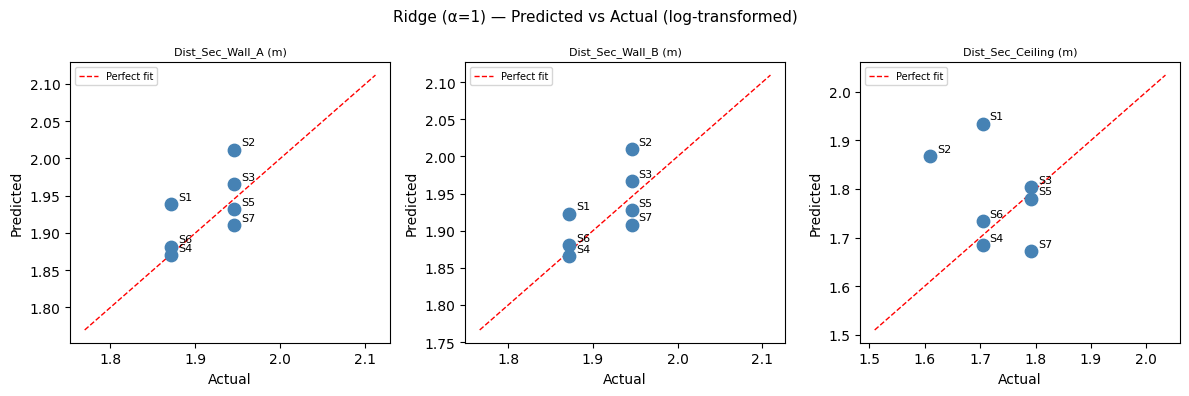

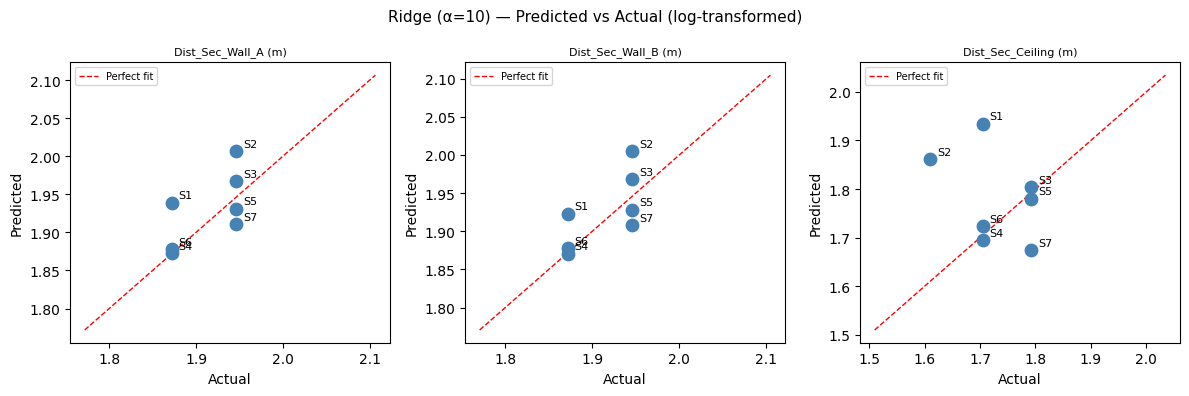

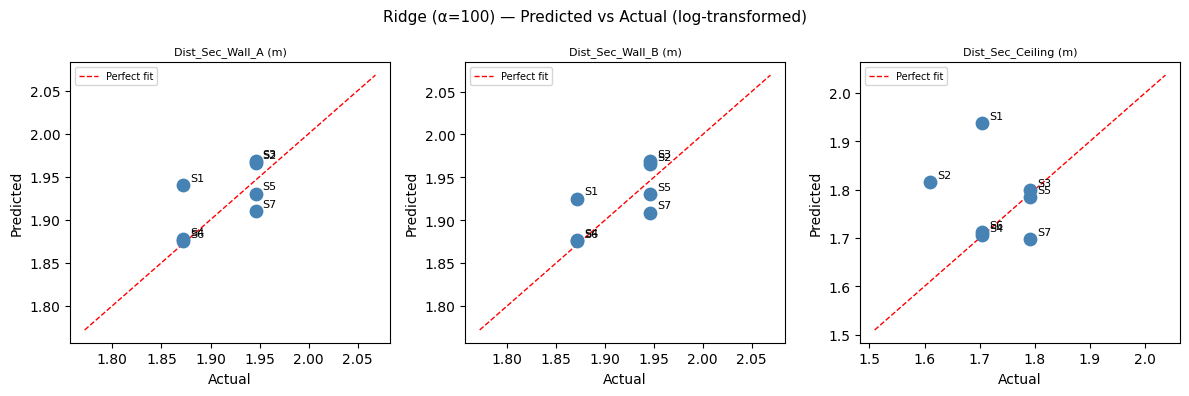

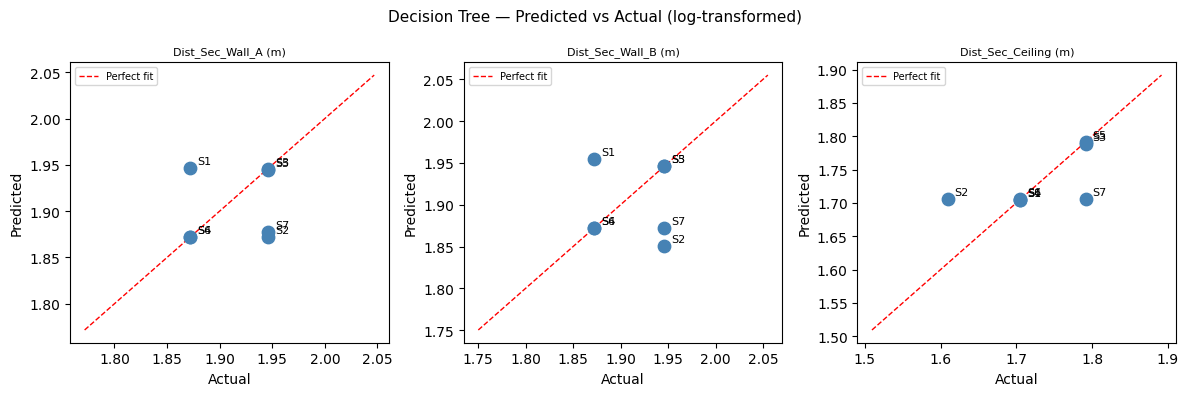

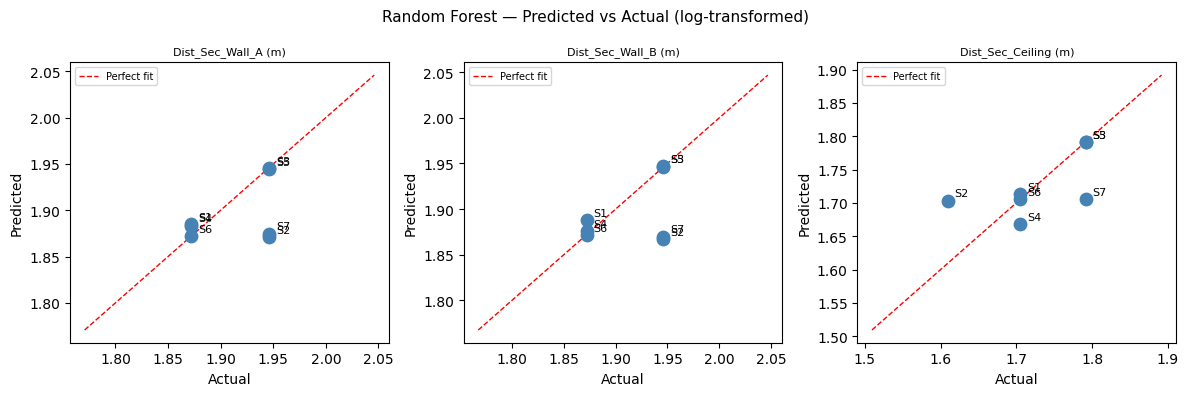

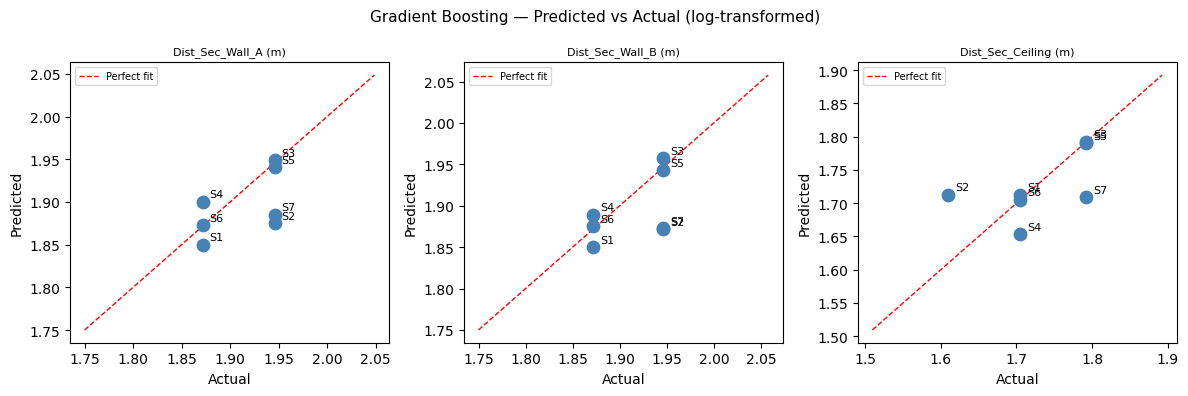

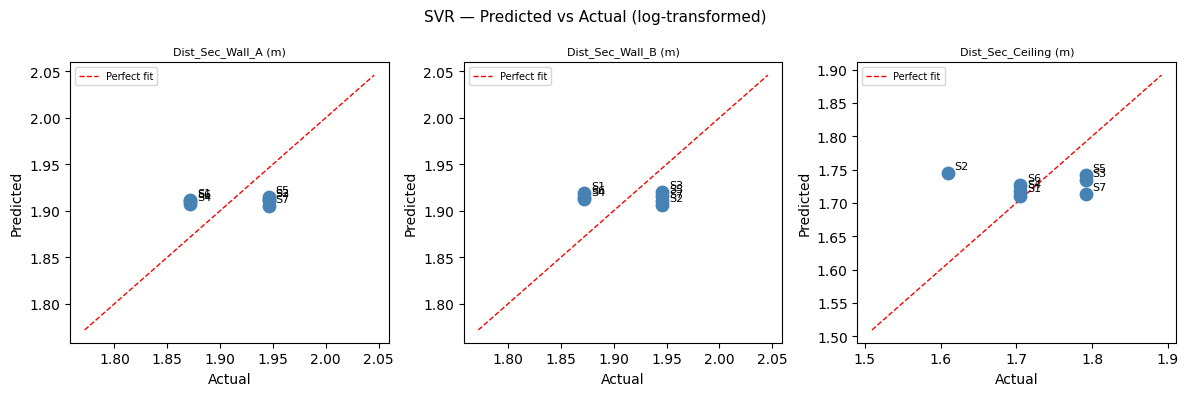

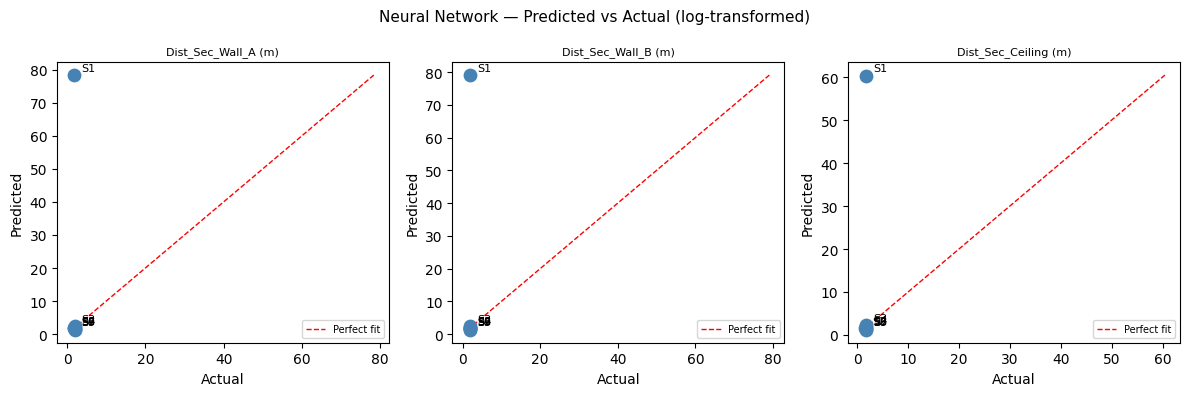

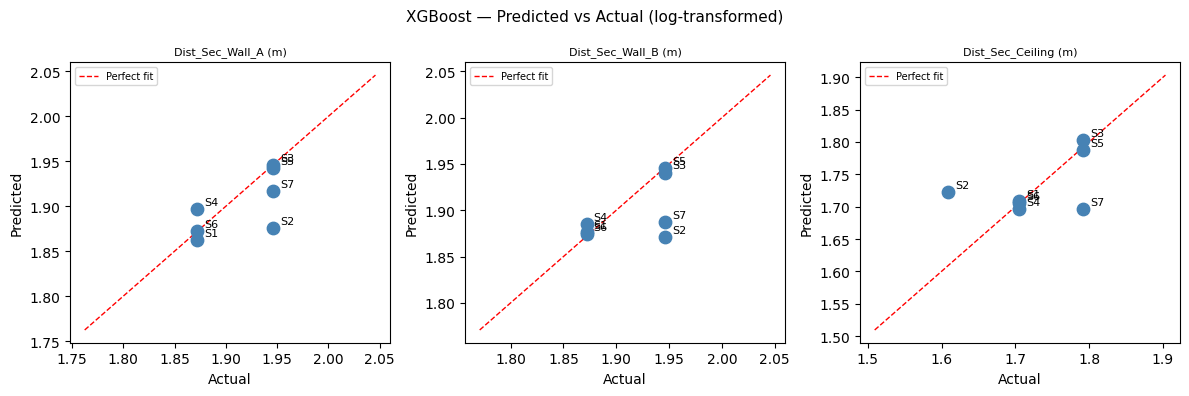

In [ ]:
# ============================================================
# BLOCK 13: Predicted vs Actual Plots (log scale)
# ============================================================

# ============================================================
# BLOCK 12: Predicted vs Actual Plots (log scale)
# ============================================================

for name, Y_pred in BEST_PREDS.items():
    n_plot = min(3, Y_transformed.shape[1])
    plt.figure(figsize=(4 * n_plot, 4))
    plt.suptitle(f"{name} — Predicted vs Actual (log-transformed)", fontsize=11)

    for i in range(n_plot):
        ax = plt.subplot(1, n_plot, i + 1)
        actual = Y_transformed.iloc[:, i].values
        predicted = Y_pred[:, i]

        ax.scatter(actual, predicted, s=80, color='steelblue', zorder=3)

        for j in range(len(actual)):
            ax.annotate(f"S{j+1}", (actual[j], predicted[j]),
                        textcoords="offset points", xytext=(5, 3), fontsize=8)

        lims = [min(actual.min(), predicted.min()) - 0.1,
                max(actual.max(), predicted.max()) + 0.1]
        ax.plot(lims, lims, 'r--', linewidth=1, label='Perfect fit')
        ax.set_xlabel("Actual")
        ax.set_ylabel("Predicted")
        ax.set_title(OUTPUT_COLS[i].replace('\n', ' '), fontsize=8)
        ax.legend(fontsize=7)

    plt.tight_layout()
    plt.show()

=== Pearson Correlation: Each Input vs Each Output ===


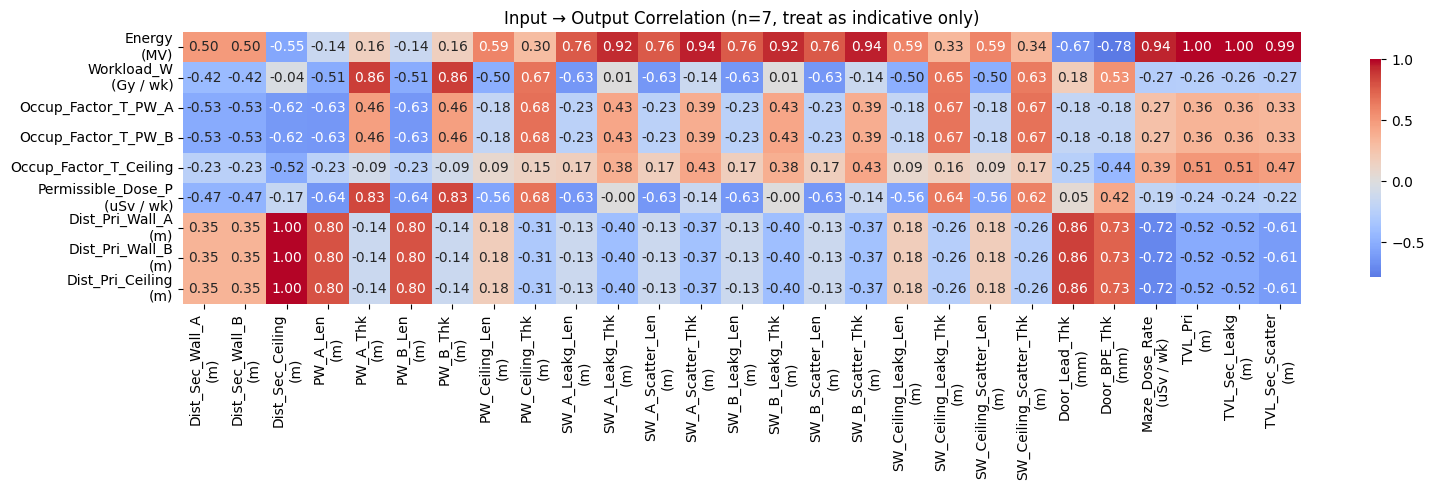


Note: With n=7, correlations > |0.7| are worth noting.
Correlations < |0.5| are likely noise.


In [ ]:
# ============================================================
# BLOCK 13: Input-Output Correlation (honest for n=7)
# ============================================================

print("=== Pearson Correlation: Each Input vs Each Output ===")
full_df = pd.concat([X_orig, Y_orig], axis=1)
corr_matrix = full_df.corr()

# Extract only input→output correlations
input_output_corr = corr_matrix.loc[INPUT_COLS, OUTPUT_COLS]

plt.figure(figsize=(16, 5))
sns.heatmap(input_output_corr, annot=True, fmt=".2f", cmap='coolwarm',
            center=0, cbar_kws={"shrink": 0.8})
plt.title('Input → Output Correlation (n=7, treat as indicative only)')
plt.tight_layout()
plt.show()

print("\nNote: With n=7, correlations > |0.7| are worth noting.")
print("Correlations < |0.5| are likely noise.")